# Question 2 — Motion or Memory?
Train a ConvLSTM on Moving MNIST, stress-test it with mirror / rotation / speed-up, find out why it fails, and fix it.

## 1. Setup

In [27]:
pip install torch torchvision opencv-python-headless matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [28]:
import os, random
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1" 

import numpy as np
import torch
import torchvision
import cv2
import matplotlib.pyplot as plt
import pandas as pd

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"                               # Apple Silicon GPU
else:
    device = "cpu"

os.makedirs("figures", exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if device == "mps":
        torch.mps.manual_seed(s)
    elif device == "cuda":
        torch.cuda.manual_seed_all(s)

set_seed(0)
print("torch", torch.__version__, "| device:", device)

torch 2.14.1 | device: mps


### Data
All 10,000 videos (20 frames, 64×64). Split **by video index**: 0–7999 train, 8000–8999 val, 9000–9999 test.

In [29]:
ds = torchvision.datasets.MovingMNIST(root="data", split=None, download=True)
data = torch.stack([ds[i] for i in range(len(ds))])   # (10000, 20, 1, 64, 64), uint8
print(data.shape, data.dtype)

train_u8, val_u8, test_u8 = data[:8000], data[8000:9000], data[9000:]

def to_float(x):
    return x.float() / 255.0  

print(len(train_u8), len(val_u8), len(test_u8))

torch.Size([10000, 20, 1, 64, 64]) torch.uint8
8000 1000 1000


### Play a random video

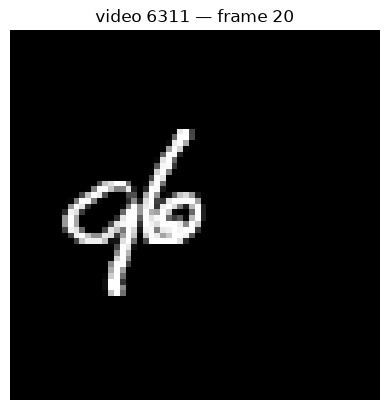

In [30]:
import time
from IPython.display import clear_output

idx = random.randint(0, len(data) - 1)

for f in range(20):
    clear_output(wait=True)
    plt.imshow(data[idx, f, 0], cmap="gray")
    plt.title(f"video {idx} — frame {f+1}")
    plt.axis("off")
    plt.show()
    time.sleep(0.2)

### Transformations
- **Mirror**: flip left ↔ right
- **Rotate**: turn 90° anticlockwise
- **Speed-up**: keep every k-th frame (digits move k times faster)

In [31]:
def mirror(x):
    return x.flip(-1)

def rotate(x, a=1):
    return torch.rot90(x, k=a, dims=(-2, -1))

def speed_up(x, k=2):
    return x[..., ::k, :, :, :]        

G, G_inv = [], []
for a in range(4):
    G.append(lambda x, a=a: rotate(x, a))              
    G_inv.append(lambda x, a=a: rotate(x, -a))          
    G.append(lambda x, a=a: mirror(rotate(x, a)))       
    G_inv.append(lambda x, a=a: mirror(rotate(x, a)))    

# quick checks
torch.manual_seed(0); _x = torch.rand(2, 20, 1, 64, 64)
assert len(G) == 8 and all(torch.equal(gi(g(_x)), _x) for g, gi in zip(G, G_inv))
assert len({g(_x).sum(dim=(0,1,2)).flatten()[:5].tolist().__str__() for g in G}) == 8 
print("G OK")

G OK


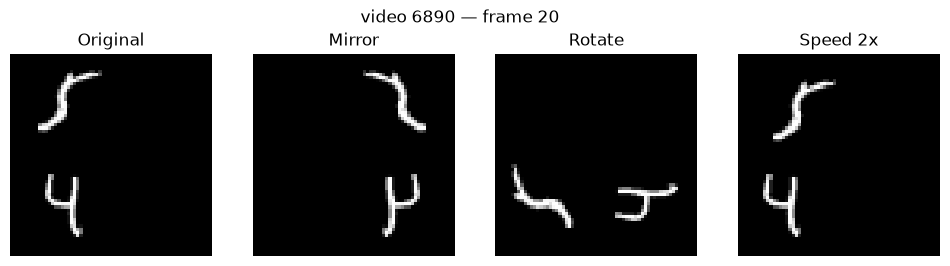

In [32]:
import time
from IPython.display import clear_output

idx = random.randint(0, len(data) - 1)
video = data[idx]                       # (20, 1, 64, 64), keep the channel

versions = {
    "Original": video,
    "Mirror":   mirror(video),
    "Rotate":   rotate(video),
    "Speed 2x": speed_up(video, 2),   
}

for f in range(20):
    clear_output(wait=True)
    fig, ax = plt.subplots(1, 4, figsize=(12, 3))
    for a, (name, vid) in zip(ax, versions.items()):
        a.imshow(vid[min(f, len(vid) - 1), 0], cmap="gray")   # ", 0" drops the channel just for display
        a.set_title(name)
        a.axis("off")
    fig.suptitle(f"video {idx} — frame {f+1}")
    plt.show()
    time.sleep(0.2)

### Checking the code (Table 1)

In [33]:
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)                

p = torch.zeros(20, 1, 64, 64)            
p[7, 0, 10, 20] = 1

v = torch.arange(1, 21).float().view(20, 1, 1, 1).repeat(1, 1, 64, 64)  
def check_a():
    out = mirror(mirror(x))
    print("(a) diff:", (out - x).abs().max().item(), "| equal:", torch.equal(out, x))

def check_b():
    out = rotate(x, 4)
    print("(b) diff:", (out - x).abs().max().item(), "| equal:", torch.equal(out, x))

def check_c():
    out = mirror(rotate(mirror(x)))
    print("(c) diff:", (out - rotate(x, -1)).abs().max().item(), "| equal:", torch.equal(out, rotate(x, -1)))

def check_d():
    f, _, r, c = torch.nonzero(mirror(p))[0].tolist()
    print("(d) dot at (frame, row, col):", (f, r, c))

def check_e():
    f, _, r, c = torch.nonzero(rotate(p))[0].tolist()
    print("(e) dot at (frame, row, col):", (f, r, c))
def get_window(video, t=1, k=1):
    assert 1 <= t and t + 4*k <= 20, "input frames must exist"
    X = [t + i*k for i in range(5)]
    Y = [t + i*k for i in range(5, 10) if t + i*k <= 20]
    return video[..., [f-1 for f in X], :, :, :], video[..., [f-1 for f in Y], :, :, :]


def check_window(k):
    X, Y = get_window(v, t=1, k=k)
    print(f"{k}x input:", X[:, 0, 0, 0].int().tolist(), "| target:", Y[:, 0, 0, 0].int().tolist())
    # Allowed start frames
T_NORMAL = list(range(1, 12))                                       
T_AUG = {k: [t for t in range(1, 21) if t + 6*k <= 20] for k in (1, 2, 3)} 

print("T_NORMAL:", T_NORMAL)
print("T_AUG:", T_AUG)

T_NORMAL: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
T_AUG: {1: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14], 2: [1, 2, 3, 4, 5, 6, 7, 8], 3: [1, 2]}


In [34]:
check_a()
check_b()
check_c()
check_d()
check_e()
check_window(1) 
check_window(2)   
check_window(3)   

(a) diff: 0.0 | equal: True
(b) diff: 0.0 | equal: True
(c) diff: 0.0 | equal: True
(d) dot at (frame, row, col): (7, 10, 43)
(e) dot at (frame, row, col): (7, 43, 10)
1x input: [1, 2, 3, 4, 5] | target: [6, 7, 8, 9, 10]
2x input: [1, 3, 5, 7, 9] | target: [11, 13, 15, 17, 19]
3x input: [1, 4, 7, 10, 13] | target: [16, 19]


**Table 1: Checks of the transformation and window functions.**

| | Check | Expected | Yours |
|---|---|---|---|
| (a) | max\|M(M(x)) − x\| | 0 | 0 (`torch.equal` = True) |
| (b) | max\|R⁴(x) − x\| | 0 | 0 (`torch.equal` = True) |
| (c) | max\|MRM(x) − R⁻¹(x)\| | 0 | 0 (`torch.equal` = True) |
| (d) | bright pixel of M(p) (frame, row, column) | (7, 10, 43) | (7, 10, 43) |
| (e) | bright pixel of R(p) (frame, row, column) | (7, 43, 10) | (7, 43, 10) |
| (f) | 1× input / target frames | 1–5 / 6–10 | 1–5 / 6–10 |
| (g) | 2× input / target frames | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 |
| (h) | 3× input / target frames | 1, 4, 7, 10, 13 / 16, 19 | 1, 4, 7, 10, 13 / 16, 19 |

All rows match the expected values.

### Is the training data already symmetric? (Figure 1)
Optical flow on the first 50 training videos (50 × 19 = 950 frame pairs).

In [35]:
dx_all, dy_all = [], []

for i in range(50):                                   # first 50 training videos
    for s in range(19):                               # 19 frame pairs per video
        a = train_u8[i, s, 0].numpy()
        b = train_u8[i, s + 1, 0].numpy()
        flow = cv2.calcOpticalFlowFarneback(a, b, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        keep = (a > 51) & (b > 51) & (np.hypot(dx, dy) > 0.5)
        dx_all.append(dx[keep])
        dy_all.append(dy[keep])

dx = np.concatenate(dx_all)
dy = np.concatenate(dy_all)
theta = np.degrees(np.arctan2(-dy, dx)) % 360          # 0° = right, 90° = up
speed = np.hypot(dx, dy)
med = np.median(speed)

print("pixels kept:", len(speed))
print(f"median speed: {med:.3g} px/frame | 2x ≈ {2*med:.3g} | 3x ≈ {3*med:.3g}")

pixels kept: 103050
median speed: 3.32 px/frame | 2x ≈ 6.64 | 3x ≈ 9.95


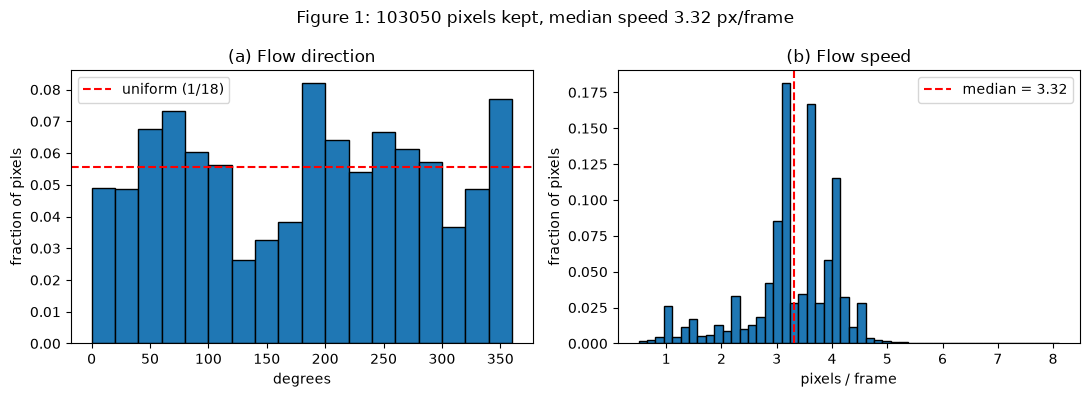

In [36]:
w = np.ones(len(speed)) / len(speed)                   # fractions, not counts

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(theta, bins=np.arange(0, 361, 20), weights=w, edgecolor="k")
ax[0].axhline(1/18, color="r", ls="--", label="uniform (1/18)")
ax[0].set(title="(a) Flow direction", xlabel="degrees", ylabel="fraction of pixels")
ax[0].legend()

ax[1].hist(speed, bins=50, weights=w, edgecolor="k")
ax[1].axvline(med, color="r", ls="--", label=f"median = {med:.3g}")
ax[1].set(title="(b) Flow speed", xlabel="pixels / frame", ylabel="fraction of pixels")
ax[1].legend()

fig.suptitle(f"Figure 1: {len(speed)} pixels kept, median speed {med:.3g} px/frame")
plt.tight_layout()
plt.savefig("figures/fig1.png", dpi=150)
plt.show()

In [37]:
counts = np.histogram(theta, bins=np.arange(0, 361, 20))[0] / len(theta)
print(f"direction bins: min {counts.min():.3g}, max {counts.max():.3g}, uniform {1/18:.3g}")
print(f"median speed {med:.3g} | 2x {2*med:.3g} | 3x {3*med:.3g}")
print(f"share between 3 and 4.5 px/frame: {100*np.mean((speed >= 3) & (speed <= 4.5)):.3g} %")
print(f"share above 5 px/frame: {100*np.mean(speed > 5):.3g} %")

direction bins: min 0.0263, max 0.082, uniform 0.0556
median speed 3.32 | 2x 6.64 | 3x 9.95
share between 3 and 4.5 px/frame: 72.2 %
share above 5 px/frame: 0.465 %


**Figure 1:** Optical flow on the first 50 training videos (950 frame pairs), pooled over 103,050 kept pixels.
(a) Flow direction (18 bins of 20°; red line = uniform level 1/18). (b) Flow speed; median = 3.32 px/frame.

### Q2.1
**Direction.** Yes, mirrored and rotated trajectories are already familiar. Every 20° bin in Figure 1(a)
is non-empty, holding between 0.0263 and 0.0820 of the kept pixels (uniform = 0.0556). A mirror maps
θ → 180° − θ, which reflects the histogram about the 90°/270° axis. A 90° rotation maps θ → θ + 90°, which
shifts it by 4.5 bins. Neither creates a direction that is missing from training, so the transformed motion
stays within what training already covers. Only the digits' appearance is new.

**Speed.** The median speed is **3.32 px/frame**. 72.2 % of kept pixels are between 3 and 4.5 px/frame,
and only 0.465 % are above 5 px/frame. So 2× ≈ **6.64 px/frame** and 3× ≈ **9.95 px/frame** are speeds the
model has essentially never seen in training.

**Overlap bias.** Where digits overlap, flow tends to underestimate speed and adds scattered directions.
The small bump near 1 px/frame in Figure 1(b) is likely this effect. It can only add low speeds and
spread directions out. It cannot create speeds of 6.6–10 px/frame or remove whole directions, so it
cannot change either conclusion.

### Q2.2
| Transformation | Changes motion statistics? | Changes appearance? |
|---|---|---|
| Mirror | No | Yes |
| Rotation | No | Yes (more) |
| Speed-up | Yes | No |

Mirror and rotation do change each digit's velocity (e.g. dx → −dx), but the **distribution** of directions and
speeds stays within what training covers (Q2.1). Each transformation changes **only one thing** and keeps the
physics the same, so if the model fails we know the cause: appearance (mirror or rotation) or motion (speed-up).

## 2. Baseline: ConvLSTM (Model A)

In [42]:
import torch.nn as nn
import torch.nn.functional as F
import time

### ConvLSTM 
One convolution makes all 4 gates (i, f, o, g) from [input, previous hidden state].

In [39]:
class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid_ch, k=3):
        super().__init__()
        self.conv = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, k, padding=k // 2)

    def forward(self, u, h, c):
        i, f, o, g = self.conv(torch.cat([u, h], dim=1)).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

### Model A
fold 4×4 patches → ConvLSTM 1 → ConvLSTM 2 → 1×1 conv → unfold → sigmoid.
Runs 9 steps: real frames for steps 1–5, its own predictions for steps 6–9. Outputs of steps 5–9 are the forecast.

In [40]:
class ModelA(nn.Module):
    def __init__(self, hid=64):
        super().__init__()
        self.hid = hid
        self.cell1 = ConvLSTMCell(16, hid)
        self.cell2 = ConvLSTMCell(hid, hid)
        self.out = nn.Conv2d(hid, 16, 1)

    def forward(self, X):                       # X: (B, 5, 1, 64, 64)
        B = X.shape[0]
        h1 = c1 = h2 = c2 = torch.zeros(B, self.hid, 16, 16, device=X.device)
        preds = []
        for step in range(9):
            frame = X[:, step] if step < 5 else pred          # real frame, then own prediction
            z = F.pixel_unshuffle(frame, 4)                    # (B, 16, 16, 16)
            h1, c1 = self.cell1(z, h1, c1)
            h2, c2 = self.cell2(h1, h2, c2)
            pred = torch.sigmoid(F.pixel_shuffle(self.out(h2), 4))   # (B, 1, 64, 64)
            if step >= 4:                                      # keep steps 5–9
                preds.append(pred)
        return torch.stack(preds, dim=1)                       # (B, 5, 1, 64, 64)

### Check: parameter count and output shape

In [41]:
model = ModelA().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("parameters:", n_params, "| expected: 480784 |", n_params == 480784)

X, Y = get_window(to_float(test_u8[:4]), t=1, k=1)      # 4 test videos
with torch.no_grad():
    out = model(X.to(device))
print("input:", tuple(X.shape), "| output:", tuple(out.shape))

parameters: 480784 | expected: 480784 | True
input: (4, 5, 1, 64, 64) | output: (4, 5, 1, 64, 64)


### Training setup
- **make_batch**: cut one random window per video (pads targets to 5 frames + a mask for frames that don't exist)
- **masked_mse**: loss over pixels and *available* target frames per video, then averaged over videos
- **train**: Adam, lr 1e-3, batch 32, 30 epochs, keep final weights

In [46]:
def make_batch(videos, speed_aug=False, sym_aug=False):
    Xs, Ys, masks = [], [], []
    for vid in videos:
        k = random.choice([1, 2, 3]) if speed_aug else 1
        t = random.choice(T_AUG[k] if speed_aug else T_NORMAL)
        X, Y = get_window(vid, t, k)
        n = len(Y)                                         
        Y = torch.cat([Y, torch.zeros(5 - n, 1, 64, 64, dtype=Y.dtype)])   # pad to 5
        if sym_aug:                                        
            g = random.choice(G)
            X, Y = g(X), g(Y)
        Xs.append(X); Ys.append(Y); masks.append(torch.arange(5) < n)
    return torch.stack(Xs), torch.stack(Ys), torch.stack(masks).float()
def masked_mse(pred, Y, mask):
    err = ((pred - Y) ** 2).mean(dim=(2, 3, 4))       
    per_video = (err * mask).sum(1) / mask.sum(1)       
    return per_video.mean()        
def sync():
    if device == "mps":  torch.mps.synchronize()
    if device == "cuda": torch.cuda.synchronize()                    

### Training function

In [44]:
os.makedirs("checkpoints", exist_ok=True)

def train(model_class, name, seed, epochs=30, speed_aug=False, sym_aug=False):
    set_seed(seed)
    model = model_class().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = {"train_loss": [], "val_E5": [], "epoch_time": []}

    for ep in range(epochs):
        model.train()
        sync(); t0 = time.time()
        perm = torch.randperm(len(train_u8))         
        total = 0
        for i in range(0, len(perm), 32):
            X, Y, M = make_batch(train_u8[perm[i:i+32]], speed_aug, sym_aug)
            X, Y, M = to_float(X.to(device)), to_float(Y.to(device)), M.to(device)
            loss = masked_mse(model(X), Y, M)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(X)
        sync(); history["epoch_time"].append(time.time() - t0)
        history["train_loss"].append(total / len(perm))

        # validation: E(5) at 1x, t=1
        model.eval()
        with torch.no_grad():
            errs = []
            for i in range(0, len(val_u8), 32):
                X, Y = get_window(to_float(val_u8[i:i+32].to(device)), 1, 1)
                errs.append(((model(X) - Y) ** 2).mean(dim=(1, 2, 3, 4)))
            history["val_E5"].append(torch.cat(errs).mean().item())

        print(f"[{name} s{seed}] epoch {ep+1}/{epochs} | train {history['train_loss'][-1]:.4g} "
              f"| val E5 {history['val_E5'][-1]:.4g} | {history['epoch_time'][-1]:.1f}s")

    torch.save({"model": model.state_dict(), "history": history}, f"checkpoints/{name}_s{seed}.pt")
    return model, history

### Train model A (seeds 0 and 1)

In [48]:
models_A, hist_A = {}, {}
for seed in [0, 1]:
    models_A[seed], hist_A[seed] = train(ModelA, "A", seed=seed, epochs=30)

[A s0] epoch 1/30 | train 0.04609 | val E5 0.03931 | 20.5s
[A s0] epoch 2/30 | train 0.03969 | val E5 0.03853 | 19.9s
[A s0] epoch 3/30 | train 0.03863 | val E5 0.03729 | 19.9s
[A s0] epoch 4/30 | train 0.03706 | val E5 0.03552 | 19.9s
[A s0] epoch 5/30 | train 0.03512 | val E5 0.03369 | 19.9s
[A s0] epoch 6/30 | train 0.03352 | val E5 0.03292 | 20.0s
[A s0] epoch 7/30 | train 0.03216 | val E5 0.03102 | 20.0s
[A s0] epoch 8/30 | train 0.03115 | val E5 0.03022 | 20.1s
[A s0] epoch 9/30 | train 0.03049 | val E5 0.02967 | 19.9s
[A s0] epoch 10/30 | train 0.02982 | val E5 0.02914 | 20.0s
[A s0] epoch 11/30 | train 0.02931 | val E5 0.02893 | 19.9s
[A s0] epoch 12/30 | train 0.02878 | val E5 0.02846 | 19.9s
[A s0] epoch 13/30 | train 0.0284 | val E5 0.02806 | 19.9s
[A s0] epoch 14/30 | train 0.02807 | val E5 0.02762 | 19.9s
[A s0] epoch 15/30 | train 0.02761 | val E5 0.02703 | 19.9s
[A s0] epoch 16/30 | train 0.02724 | val E5 0.02686 | 19.9s
[A s0] epoch 17/30 | train 0.02677 | val E5 0.0264

**Hardware:** Apple M2 Pro, MPS backend, PyTorch 2.14.1. Training time: 19.9 s/epoch (seed 0), 19.8 s/epoch (seed 1).

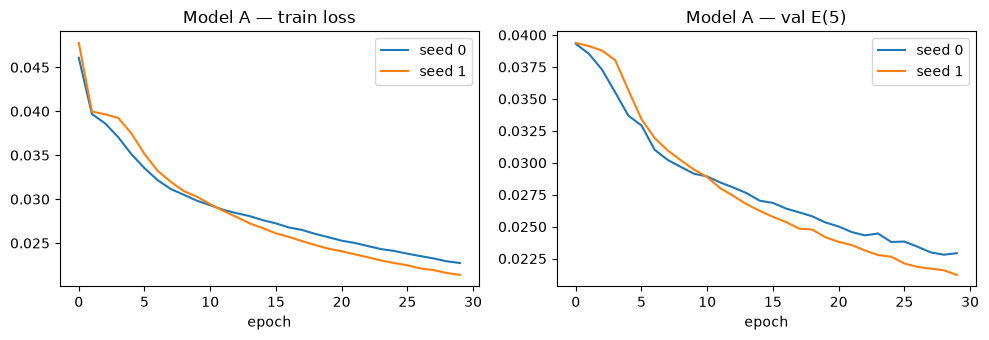

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for s in [0, 1]:
    ax[0].plot(hist_A[s]["train_loss"], label=f"seed {s}")
    ax[1].plot(hist_A[s]["val_E5"], label=f"seed {s}")
ax[0].set(title="Model A — train loss", xlabel="epoch")
ax[1].set(title="Model A — val E(5)", xlabel="epoch")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

### Evaluation on the test set

In [ ]:
def blank(X):
    return torch.zeros_like(X)                

def copy_last(X):
    return X[:, -1:].repeat(1, 5, 1, 1, 1)  
def eval_mse(f, videos=test_u8, t=1, k=1, T=None):
    out = []
    with torch.no_grad():
        for i in range(0, len(videos), 32):
            X, Y = get_window(to_float(videos[i:i+32].to(device)), t, k)
            if T is not None:                    
                X, Y = T(X), T(Y)
            pred = f(X)[:, :Y.shape[1]]            
            out.append(((pred - Y) ** 2).mean(dim=(2, 3, 4)).cpu())
    return torch.cat(out)     
def fmt(v):
    return f"{v:.2e}" if 0 < abs(v) < 1e-3 else f"{v:#.3g}"
def fmt_seeds(v0, v1):
    return f"{fmt((v0 + v1) / 2)} ({fmt(v0)}, {fmt(v1)})"   

### Table 2

In [52]:
for m in models_A.values():
    m.eval()

mse = {
    "A_s0":      eval_mse(models_A[0]).mean(0),    
    "A_s1":      eval_mse(models_A[1]).mean(0),
    "Blank":     eval_mse(blank).mean(0),
    "Copy-last": eval_mse(copy_last).mean(0),
}

rows = []
rows.append(["A"] + [fmt_seeds(mse["A_s0"][h].item(), mse["A_s1"][h].item()) for h in range(5)]
            + [fmt_seeds(mse["A_s0"].mean().item(), mse["A_s1"].mean().item()), n_params])
for name in ["Blank", "Copy-last"]:
    rows.append([name] + [fmt(mse[name][h].item()) for h in range(5)] + [fmt(mse[name].mean().item()), 0])

table2 = pd.DataFrame(rows, columns=["Model", "MSE1", "MSE2", "MSE3", "MSE4", "MSE5", "E(5)", "Params"])
table2

,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E(5),Params
0,A,"0.0171 (0.0177, 0.0165)","0.0205 (0.0213, 0.0197)","0.0228 (0.0237, 0.0219)","0.0247 (0.0256, 0.0237)","0.0265 (0.0275, 0.0255)","0.0223 (0.0232, 0.0214)",480784
1,Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
2,Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


### Figure 2 — predictions on three test videos

In [53]:

bright = (test_u8[:, :, 0] > 51).sum(dim=(2, 3)).float()         
drop = 1 - bright[:, 5:10].min(1).values / bright.max(1).values
print("videos with overlap in frames 6–10:", (drop.argsort(descending=True)[:10]).tolist())

videos with overlap in frames 6–10: [851, 840, 216, 313, 349, 202, 534, 531, 782, 405]


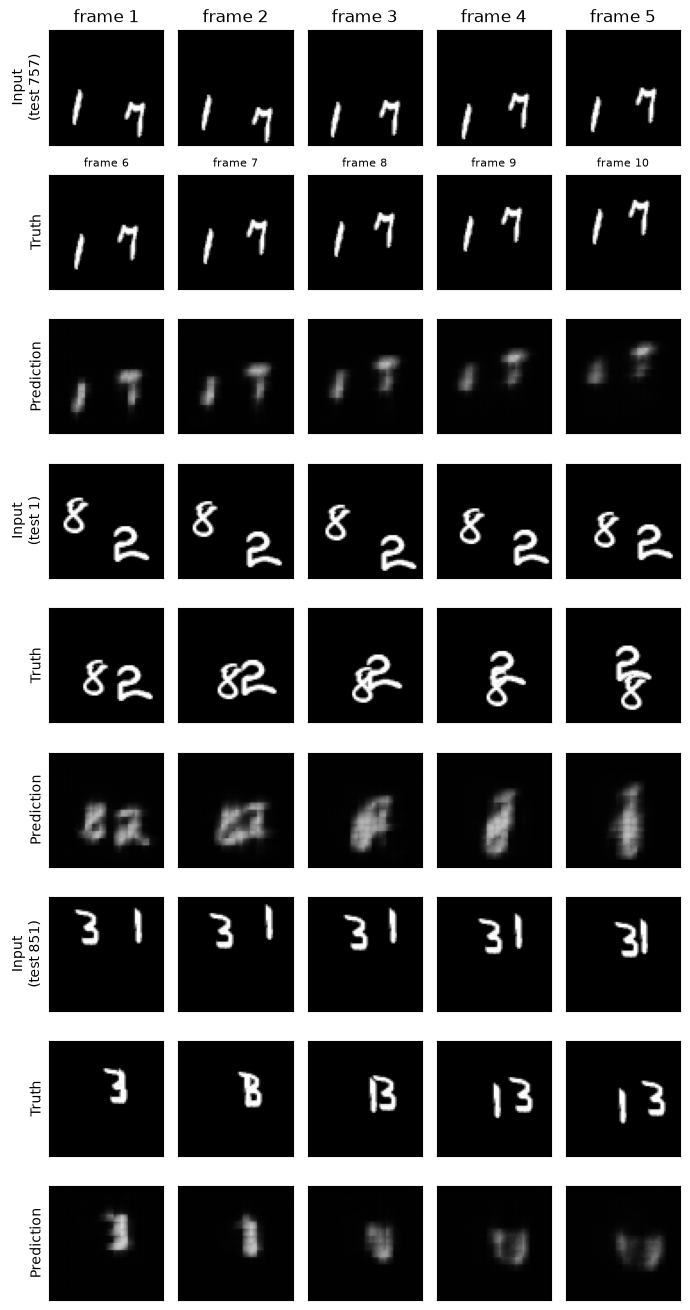

In [58]:
def plot_predictions(model, vids, fname):
    fig, ax = plt.subplots(3 * len(vids), 5, figsize=(7, 4.4 * len(vids)))
    for r, v in enumerate(vids):
        X, Y = get_window(to_float(test_u8[v:v+1].to(device)), 1, 1)
        with torch.no_grad():
            P = model(X)
        for c in range(5):
            for j, (name, img) in enumerate([("Input", X), ("Truth", Y), ("Prediction", P)]):
                a = ax[3*r + j, c]
                a.imshow(img[0, c, 0].cpu(), cmap="gray", vmin=0, vmax=1)
                a.set_xticks([]); a.set_yticks([])
                if c == 0: a.set_ylabel(f"{name}\n(test {v})" if j == 0 else name)
                if r == 0 and j == 0: a.set_title(f"frame {c+1}")
                if r == 0 and j == 1: a.set_title(f"frame {c+6}", fontsize=8)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

overlap_vid = drop.argsort(descending=True)[0].item()
plot_predictions(models_A[0], [757, 1, overlap_vid], "figures/fig2.png")

**Table 2:** Test-set error (1×, t = 1) per forecast horizon and E(5). Model A entries are mean (seed 0, seed 1).

**Figure 2:** Seed-0 model A on test videos 757, 1 and 851. Rows: input frames 1–5, true future frames 6–10,
prediction. Video 757 has no overlap; in videos 1 and 851 the digits overlap in the future frames.

### Q2.3
- `pixel_unshuffle(4)` turns each 4×4 patch into one cell, so **1 cell = 4 pixels**. Folding, unfolding and the 1×1 conv move nothing.
- Each 3×3 conv moves information at most 1 cell, including diagonally.
- Paths within one step: u_τ → conv 1 → conv 2 = **2 convs**; h⁽¹⁾_{τ−1} → conv 1 → conv 2 = **2 convs**;
  h⁽²⁾_{τ−1} → conv 2 = 1 conv. The cell states c are updated element-wise and move nothing.
- So the longest path is 2 convs: **2 cells = 8 px along rows or columns**, and **2√2 cells ≈ 11.3 px diagonally**.

So reach depends on direction: 8 px for horizontal/vertical motion, up to 11.3 px diagonally.
1× (3.32 px/frame) and 2× (6.64 px/frame) are within reach. 3× (9.95 px/frame) exceeds the reach for
horizontal/vertical motion and is close to the diagonal limit, so most 3× motion is at or beyond reach.

### Q2.4
Model A beats both references: E(5) = 0.0223, about half of Blank (0.0426) and a third of Copy-last (0.0641).
Copy-last is worse than Blank because a moved digit is penalised twice: once where it was copied and once where it should be.
A's error grows from 0.0171 (h = 1) to 0.0265 (h = 5), about +55 %, because it feeds back its own blurry predictions.
Figure 2 shows predictions blurring and fading with each frame, with a visible 4×4 block pattern from pixel_shuffle.
When digits overlap, A merges them into one blob and cannot separate them: in video 851 the 3 and 1 overlap at
frame 6 and the 1 never reappears, even though they separate in the truth. In video 1 the 8 and 2 merge into one
vertical blob. Validation E(5) was still falling at epoch 30, so A is somewhat undertrained, which may explain the seed gap
(0.0232 vs 0.0214).

### Q2.5 (written before running Testing the Baseline)
- **Mirror: passes, mostly.** The motion is familiar (Fig. 1a) and only the digit shapes are new, so E_M is a little above 0.0223 and C_M is small.
- **Rotation: fails partly.** The motion is familiar, but the digits look even less familiar, so E_R > E_M and C_R > C_M.
- **Speed:** 2× (6.64 px) is within reach but outside the training speeds, so I expect clear degradation.
  At 3× (9.95 px), horizontal/vertical motion exceeds the 8 px reach, so I expect it to break down: digits stall, blur or vanish.

In [ ]:
def load(model_class, name, seed):
    m = model_class().to(device)
    m.load_state_dict(torch.load(f"checkpoints/{name}_s{seed}.pt", map_location=device)["model"])
    return m.eval()

models_A = {s: load(ModelA, "A", s) for s in [0, 1]}

## 3. Testing the Baseline
### Mirror and rotation
C_T = MSE(f(T(X)), T(f(X))) — consistency;  E_T = MSE(f(T(X)), T(Y)) — correctness. At 1×, t = 1.

In [61]:
mirror_T = mirror
rotate_T = lambda x: rotate(x, 1)

def eval_CE(f, T, videos=test_u8):
    C, E = [], []
    with torch.no_grad():
        for i in range(0, len(videos), 32):
            X, Y = get_window(to_float(videos[i:i+32].to(device)), 1, 1)
            p = f(T(X))
            C.append(((p - T(f(X))) ** 2).mean(dim=(1, 2, 3, 4)).cpu())
            E.append(((p - T(Y)) ** 2).mean(dim=(1, 2, 3, 4)).cpu())
    return torch.cat(C), torch.cat(E)

In [62]:
predictors = {"A_s0": models_A[0], "A_s1": models_A[1], "Blank": blank, "Copy-last": copy_last}
res = {}
for name, f in predictors.items():
    CM, EM = eval_CE(f, mirror_T)
    CR, ER = eval_CE(f, rotate_T)
    res[name] = {"E5": eval_mse(f).mean().item(), "CM": CM, "EM": EM, "CR": CR, "ER": ER}

cols = ["E5", "CM", "EM", "CR", "ER"]
val = lambda name, c: res[name][c] if c == "E5" else res[name][c].mean().item()

rows = [["A"] + [fmt_seeds(val("A_s0", c), val("A_s1", c)) for c in cols]]
rows += [[n] + [fmt(val(n, c)) for c in cols] for n in ["Blank", "Copy-last"]]
table3 = pd.DataFrame(rows, columns=["Model", "E(5)", "C_M", "E_M", "C_R", "E_R"])
table3

,Model,E(5),C_M,E_M,C_R,E_R
0,A,"0.0223 (0.0232, 0.0214)","0.00185 (0.00155, 0.00216)","0.023 (0.0236, 0.0223)","0.00326 (0.00297, 0.00356)","0.0241 (0.0248, 0.0234)"
1,Blank,0.0426,0.00e+00,0.0426,0.00e+00,0.0426
2,Copy-last,0.0641,0.00e+00,0.0641,0.00e+00,0.0641


### Figure 3 (4 rows × 10 frames per video) + GIFs

largest C_M: [493, 547] | largest C_R: [36, 928]


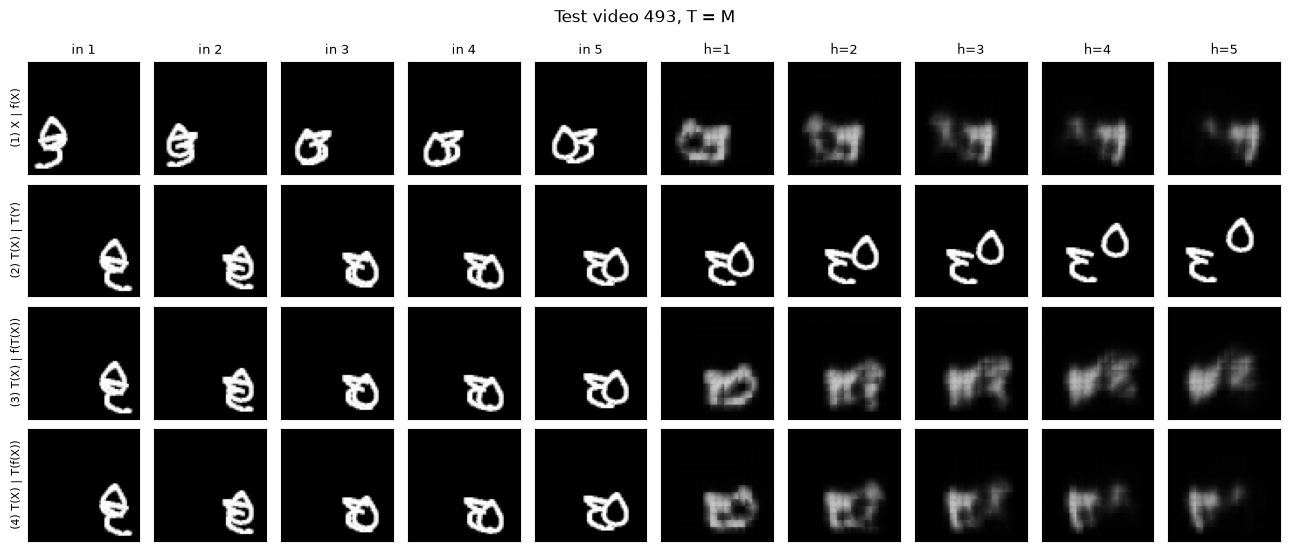

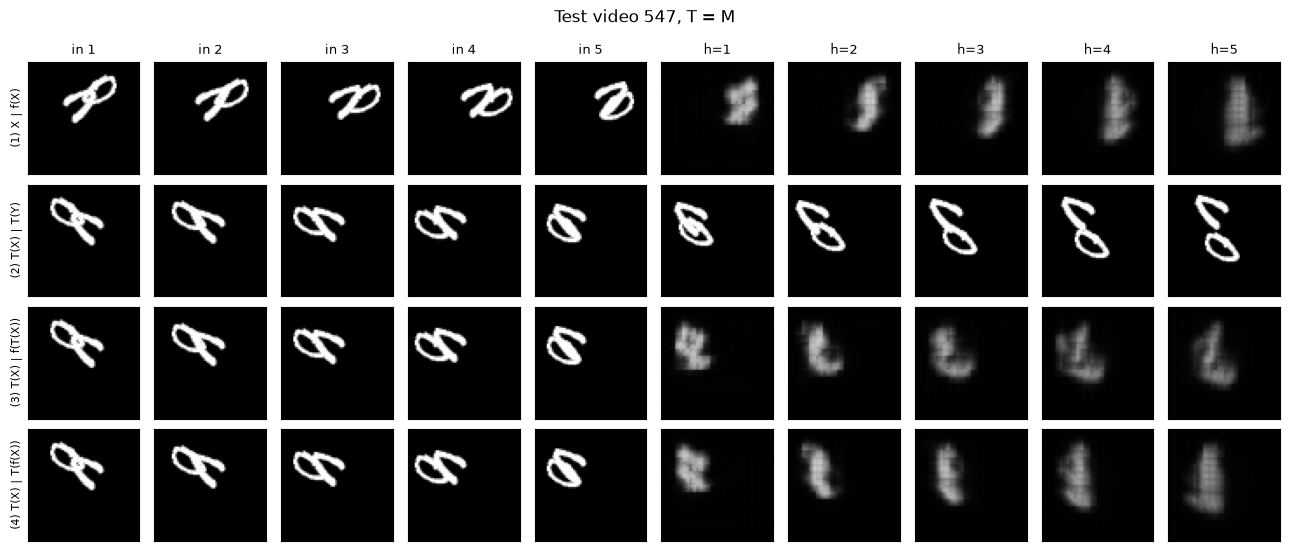

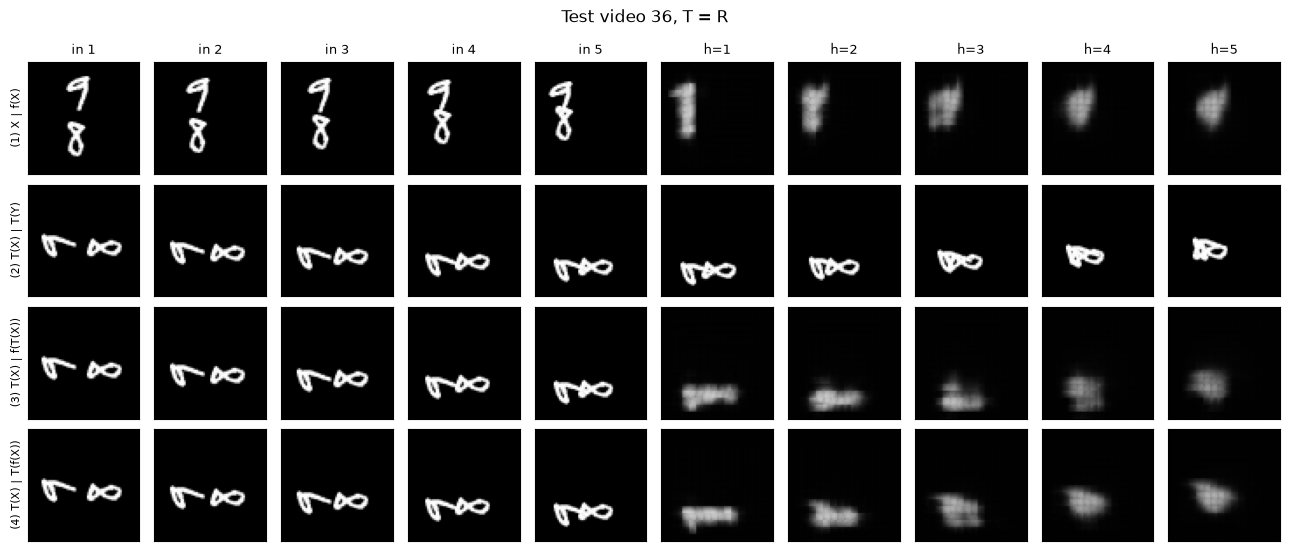

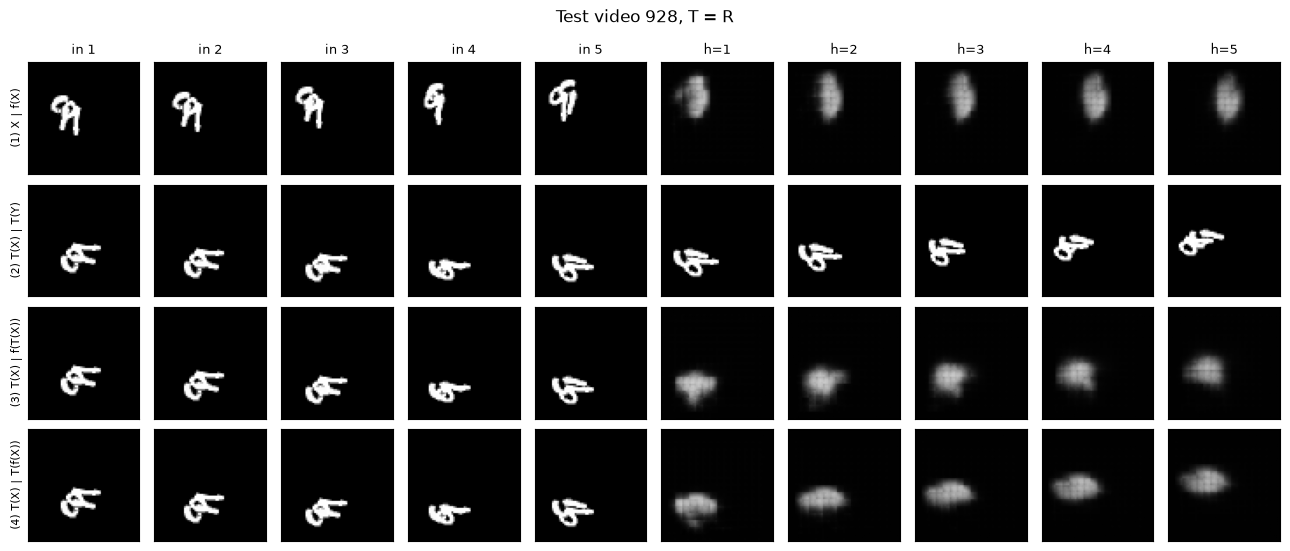

In [63]:
from matplotlib.animation import FuncAnimation, PillowWriter
os.makedirs("figures/gifs", exist_ok=True)

def four_rows(f, v, T):
    X, Y = get_window(to_float(test_u8[v:v+1].to(device)), 1, 1)
    with torch.no_grad():
        fX, fTX = f(X), f(T(X))
    rows = [(X, fX, "X | f(X)"), (T(X), T(Y), "T(X) | T(Y)"),
            (T(X), fTX, "T(X) | f(T(X))"), (T(X), T(fX), "T(X) | T(f(X))")]
    return [(torch.cat([a, b], 1)[0, :, 0].cpu(), name) for a, b, name in rows]   # each (10, 64, 64)

def plot_panel(f, v, T, Tname, fname):
    rows = four_rows(f, v, T)
    fig, ax = plt.subplots(4, 10, figsize=(13, 5.6))
    for r, (frames, name) in enumerate(rows):
        for c in range(10):
            ax[r, c].imshow(frames[c], cmap="gray", vmin=0, vmax=1)
            ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
            if r == 0: ax[r, c].set_title(f"in {c+1}" if c < 5 else f"h={c-4}", fontsize=9)
        ax[r, 0].set_ylabel(f"({r+1}) {name}", fontsize=8)
    fig.suptitle(f"Test video {v}, T = {Tname}")
    plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()

def save_gif(f, v, T, Tname, fname):
    rows = four_rows(f, v, T)
    fig, ax = plt.subplots(4, 1, figsize=(2.2, 8))
    ims = [ax[r].imshow(rows[r][0][5], cmap="gray", vmin=0, vmax=1) for r in range(4)]
    for r in range(4):
        ax[r].set_title(f"({r+1}) {rows[r][1]}", fontsize=7); ax[r].axis("off")
    def update(h):
        for r in range(4): ims[r].set_data(rows[r][0][5 + h])
        fig.suptitle(f"video {v}, {Tname}, h={h+1}", fontsize=8)
    FuncAnimation(fig, update, frames=5).save(fname, writer=PillowWriter(fps=1))
    plt.close(fig)

top_M = res["A_s0"]["CM"].argsort(descending=True)[:2].tolist()
top_R = res["A_s0"]["CR"].argsort(descending=True)[:2].tolist()
print("largest C_M:", top_M, "| largest C_R:", top_R)

for T, Tname, vids in [(mirror_T, "M", top_M), (rotate_T, "R", top_R)]:
    for v in vids:
        plot_panel(models_A[0], v, T, Tname, f"figures/fig3_{Tname}_{v}.png")
        save_gif(models_A[0], v, T, Tname, f"figures/gifs/fig3_{Tname}_{v}.gif")

### Figure 4 (histograms of C_M and C_R)

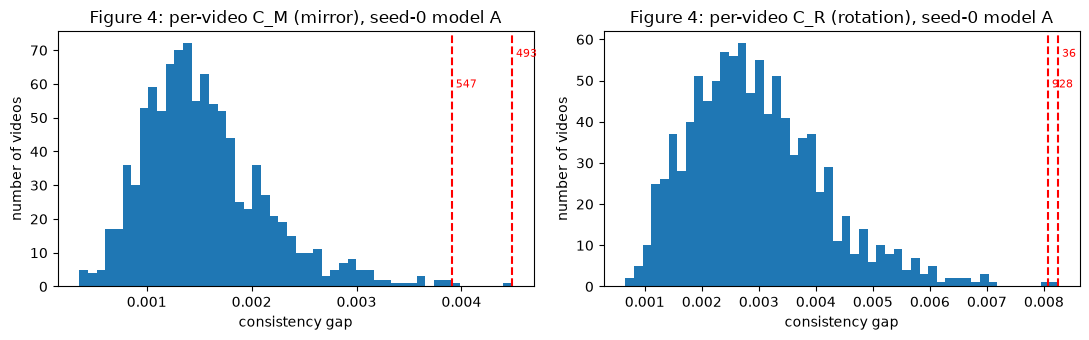

In [67]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, key, vids, title in [(ax[0], "CM", top_M, "C_M (mirror)"), (ax[1], "CR", top_R, "C_R (rotation)")]:
    C = res["A_s0"][key]
    a.hist(C.numpy(), bins=50)
    for j, v in enumerate(vids):
        a.axvline(C[v].item(), color="r", ls="--")
        a.text(C[v].item(), a.get_ylim()[1] * (0.9 - 0.12 * j), f" {v}", color="r", fontsize=8)
    a.set(title=f"Figure 4: per-video {title}, seed-0 model A", xlabel="consistency gap", ylabel="number of videos")
plt.tight_layout(); plt.savefig("figures/fig4.png", dpi=150); plt.show()

### Faster motion

In [68]:
def E_at(f, k, n):                   
    return eval_mse(f, k=k).mean(0)[:n].mean().item()

rows = []
for name, fs in [("A", [models_A[0], models_A[1]]), ("Blank", [blank]), ("Copy-last", [copy_last])]:
    vals = [[E_at(f, 1, 2) for f in fs], [E_at(f, 2, 2) for f in fs], [E_at(f, 3, 2) for f in fs],
            [E_at(f, 1, 5) for f in fs], [E_at(f, 2, 5) for f in fs]]
    rows.append([name] + [fmt_seeds(*v) if len(v) == 2 else fmt(v[0]) for v in vals])

table4 = pd.DataFrame(rows, columns=["Model", "E(2) 1x", "E(2) 2x", "E(2) 3x", "E(5) 1x", "E(5) 2x"])
table4

,Model,E(2) 1x,E(2) 2x,E(2) 3x,E(5) 1x,E(5) 2x
0,A,"0.0188 (0.0195, 0.0181)","0.0432 (0.0433, 0.0431)","0.0478 (0.0492, 0.0464)","0.0223 (0.0232, 0.0214)","0.0471 (0.0473, 0.047)"
1,Blank,0.0426,0.0425,0.0426,0.0426,0.0425
2,Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719


Figure 5 video: 946


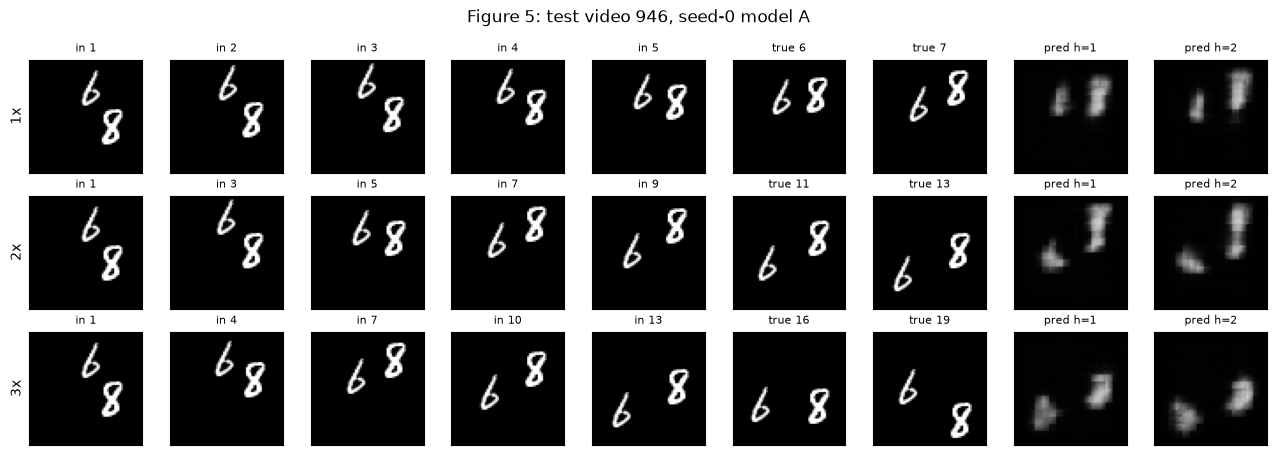

In [69]:
shown = [5, 6, 10, 12, 15, 18]                   
drop5 = 1 - bright[:, shown].min(1).values / bright.max(1).values
v5 = 946                                           # digits >=9 px apart in true frames 6,7,11,13,16,19 (bounding-box check)                     
print("Figure 5 video:", v5)

fig, ax = plt.subplots(3, 9, figsize=(13, 4.6))
for r, k in enumerate([1, 2, 3]):
    X, Y = get_window(to_float(test_u8[v5:v5+1].to(device)), 1, k)
    with torch.no_grad():
        P = models_A[0](X)
    imgs = [X[0, i] for i in range(5)] + [Y[0, 0], Y[0, 1], P[0, 0], P[0, 1]]
    names = [f"in {1+i*k}" for i in range(5)] + [f"true {1+5*k}", f"true {1+6*k}", "pred h=1", "pred h=2"]
    for c in range(9):
        ax[r, c].imshow(imgs[c][0].cpu(), cmap="gray", vmin=0, vmax=1)
        ax[r, c].set_title(names[c], fontsize=8); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
    ax[r, 0].set_ylabel(f"{k}x")
fig.suptitle(f"Figure 5: test video {v5}, seed-0 model A")
plt.tight_layout(); plt.savefig("figures/fig5.png", dpi=150); plt.show()

**Table 3:** Test-set E(5), consistency gaps C_M, C_R and transformed errors E_M, E_R (1×, t = 1). Model A: mean (seed 0, seed 1).

**Figure 3:** Seed-0 model A on the two test videos with the largest C_M (493, 547) and the largest C_R (36, 928).
Rows: (1) X | f(X), (2) T(X) | T(Y), (3) T(X) | f(T(X)), (4) T(X) | T(f(X)). GIFs: figures/gifs/fig3_M_493.gif,
figures/gifs/fig3_M_547.gif, figures/gifs/fig3_R_36.gif, figures/gifs/fig3_R_928.gif.

**Figure 4:** Per-video C_M and C_R of seed-0 model A over the 1,000 test videos; red lines mark the Figure 3 videos.

**Table 4:** Model A at different speeds (t = 1), with Blank and Copy-last for comparison. Model A: mean (seed 0, seed 1).

**Figure 5:** Test video 946 (digits do not overlap in any displayed true frame) at 1×, 2× and 3×: five input frames, first two true future frames, first two predictions (seed-0 model A).

### Q2.6
Blank and Copy-last have C_M = C_R = 0 but the worst errors (E = 0.0426 and 0.0641). A trivial model can be perfectly
consistent while being useless, so a small C_T alone does not mean the model learned motion. E_T must be reported next
to it to show the consistent predictions are also correct.

### Q2.7 (seed-0 model A, test video 493, mirror, 1×, t = 1)
In the truth (row 2) the two overlapping digits separate: the "O" moves up and to the right, and the other digit moves left.
Predicting on the mirrored input (row 3) gives one wide blob that stays low and never separates; the "O" never moves up.
Mirroring the normal prediction (row 4) gives two faint clumps drifting apart, although the "O" does not move up there
either. So on the mirrored clip the model merges both digits into a single smear, while on the original clip it at least
keeps two separate clumps. The video starts with the digits overlapping (frames 1–5), the same situation that broke
model A in Q2.4.

### Q2.8
Yes, for model A at 1× (t = 1). C_R = 0.00326 is about 1.8× C_M = 0.00185, and E_R = 0.0241 > E_M = 0.0230. This holds
for both seeds (C_R / C_M = 1.92 for seed 0 and 1.65 for seed 1), and Figure 4 shows the whole C_R distribution shifted right. The motion is equally familiar under both (Q2.1: every direction occurs in training), so
the difference comes from appearance: rotated digits look less like the training digits than mirrored ones (Q2.2).

### Q2.9
Model A falls apart at 2×, not 3×: E(2) rises from 0.0188 (1×) to 0.0432 (2×), slightly worse than Blank at the same
speed (Table 4), and to 0.0478 at 3×. This disagrees with Q2.3, because 2× (6.64 px/frame) is within both the 8 px
(horizontal/vertical) and the 11.3 px (diagonal) reach. The estimate missed that reach is only an
upper limit: the network must also have learned to use it, and it was trained only on speeds around 3.3 px/frame.
In Figure 5 (video 946), at 1× the 6 and the 8 are blurry but in roughly the right places. At 2× and 3× they stay two
separate blobs, but both stall near their last input positions: at 2× the 6 and the 8 should keep moving down, and at 3×
the 6 should bounce back up and the 8 should move to the bottom right. Their shapes also dissolve into blobs. A digit
that stalls suggests the model moves digits by at most its familiar training speed. The blurred blobs suggest it is
unsure where the digit went and averages over possible positions instead of tracking it.

### Q2.10
No. Fast motion was never in training and 3× is also beyond the reach, so both explanations predict failure. (The failure
at 2×, which is within reach, does hint that unfamiliarity matters.) Experiment: train the same architecture on 1×, 2× and
3× clips (model C). If C fixes 2× and 3×, the cause is unfamiliar motion. If C fixes 2× but still fails at 3×, while a
larger-reach model trained the same way (model D) succeeds, the 3× failure is architectural reach.